# Day 76: Google Play Store analysis

The lecture steps, run through the `play_store` package. The data path comes from `PLAY_STORE_DATA` (default `data/apps.csv`).

In [26]:
import os

from play_store.infrastructure.data import load_apps

DATA_PATH = os.environ.get("PLAY_STORE_DATA", "data/apps.csv")
df = load_apps(DATA_PATH)

## Step 1: Explore the raw data

Shape, columns and a random sample of five apps.

In [27]:
df.shape

(10841, 12)

In [28]:
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size_MBs', 'Installs', 'Type',
       'Price', 'Content_Rating', 'Genres', 'Last_Updated', 'Android_Ver'],
      dtype='str')

In [29]:
df.sample(5)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Last_Updated,Android_Ver
6403,Sid Story,GAME,4.4,28510,78.0,"500,000",Free,0,Teen,Card,"August 1, 2018",4.0.3 and up
128,CQ ESPM,BUSINESS,5.0,2,3.4,5,Free,0,Everyone,Business,"June 3, 2017",4.1 and up
4519,SarashpazPapion (Cooking with Chef Bowls),FOOD_AND_DRINK,4.8,1250,13.0,"50,000",Free,0,Everyone,Food & Drink,"July 28, 2018",4.1 and up
3460,Bubble Bo-Bo,FAMILY,4.5,65,24.0,"10,000",Free,0,Everyone,Casual,"July 5, 2018",4.0 and up
7149,"Learn Japanese, Korean, Chinese Offline & Free",EDUCATION,4.9,133136,26.0,"1,000,000",Free,0,Everyone,Education;Education,"July 20, 2018",4.2 and up


## Step 2: Clean the data

Drop the unused columns, the rows with a missing rating and the duplicates.

In [30]:
from play_store.application.cleaning import (
    add_revenue_estimate,
    convert_installs,
    convert_price,
    drop_missing_ratings,
    drop_unused_columns,
    find_duplicates,
    remove_duplicates,
    remove_expensive_apps,
)

df = drop_unused_columns(df)
df.shape

(10841, 10)

In [31]:
df = drop_missing_ratings(df)
df.shape

(9367, 10)

In [32]:
find_duplicates(df).shape

(1956, 10)

In [33]:
find_duplicates(df)[find_duplicates(df)["App"] == "Instagram"]

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres
10806,Instagram,SOCIAL,4.5,66577313,5.3,"1,000,000,000",Free,0,Teen,Social
10808,Instagram,SOCIAL,4.5,66577446,5.3,"1,000,000,000",Free,0,Teen,Social
10809,Instagram,SOCIAL,4.5,66577313,5.3,"1,000,000,000",Free,0,Teen,Social
10810,Instagram,SOCIAL,4.5,66509917,5.3,"1,000,000,000",Free,0,Teen,Social


In [34]:
df = remove_duplicates(df)
find_duplicates(df).shape

(0, 10)

Installs and Price become numbers; the 'I am Rich' apps are removed; the revenue is estimated as Installs times Price.

In [35]:
df = convert_price(convert_installs(df))
df = remove_expensive_apps(df)
df = add_revenue_estimate(df)
df.shape

(8184, 11)

## Step 3: Highest rated apps

In [36]:
from play_store.application.exploration import (
    highest_rated,
    largest_apps,
    most_reviewed,
    top_grossing_paid_apps,
)

highest_rated(df)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Revenue_Estimate
21,KBA-EZ Health Guide,MEDICAL,5.0,4,25.0,1,Free,0.00,Everyone,Medical,0.00
28,Ra Ga Ba,GAME,5.0,2,20.0,1,Paid,1.49,Everyone,Arcade,1.49
3115,Oración CX,LIFESTYLE,5.0,103,3.8,5000,Free,0.00,Everyone,Lifestyle,0.00
261,Monster Ride Pro,GAME,5.0,1,24.0,10,Free,0.00,Everyone,Racing,0.00
265,FAST EO,EVENTS,5.0,1,6.3,10,Free,0.00,Everyone,Events,0.00


## Step 4: Largest apps

In [37]:
largest_apps(df)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Revenue_Estimate
1795,Navi Radiography Pro,MEDICAL,4.7,11,100.0,500,Paid,15.99,Everyone,Medical,7995.0
7928,Stickman Legends: Shadow Wars,GAME,4.4,38419,100.0,1000000,Paid,0.99,Everyone 10+,Action,990000.0
10688,Hungry Shark Evolution,GAME,4.5,6074627,100.0,100000000,Free,0.00,Teen,Arcade,0.0
3144,Vi Trainer,HEALTH_AND_FITNESS,3.6,124,100.0,5000,Free,0.00,Everyone,Health & Fitness,0.0
9944,Gangster Town: Vice District,FAMILY,4.3,65146,100.0,10000000,Free,0.00,Mature 17+,Simulation,0.0


## Step 5: Most reviewed apps

In [38]:
most_reviewed(df, 10)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Revenue_Estimate
10805,Facebook,SOCIAL,4.1,78158306,5.30,1000000000,Free,0.0,Teen,Social,0.0
10785,WhatsApp Messenger,COMMUNICATION,4.4,69119316,3.50,1000000000,Free,0.0,Everyone,Communication,0.0
10808,Instagram,SOCIAL,4.5,66577446,5.30,1000000000,Free,0.0,Teen,Social,0.0
10790,Messenger – Text and Video Chat for Free,COMMUNICATION,4.0,56646578,3.50,1000000000,Free,0.0,Everyone,Communication,0.0
10652,Clash of Clans,GAME,4.6,44893888,98.00,100000000,Free,0.0,Everyone 10+,Strategy,0.0
10744,Clean Master- Space Cleaner & Antivirus,TOOLS,4.7,42916526,3.40,500000000,Free,0.0,Everyone,Tools,0.0
10839,Subway Surfers,GAME,4.5,27725352,76.00,1000000000,Free,0.0,Everyone 10+,Arcade,0.0
10828,YouTube,VIDEO_PLAYERS,4.3,25655305,4.65,1000000000,Free,0.0,Teen,Video Players & Editors,0.0
10746,"Security Master - Antivirus, VPN, AppLock, Boo...",TOOLS,4.7,24900999,3.40,500000000,Free,0.0,Everyone,Tools,0.0
10588,Clash Royale,GAME,4.6,23136735,97.00,100000000,Free,0.0,Everyone 10+,Strategy,0.0


## Step 6: Content rating as a pie chart

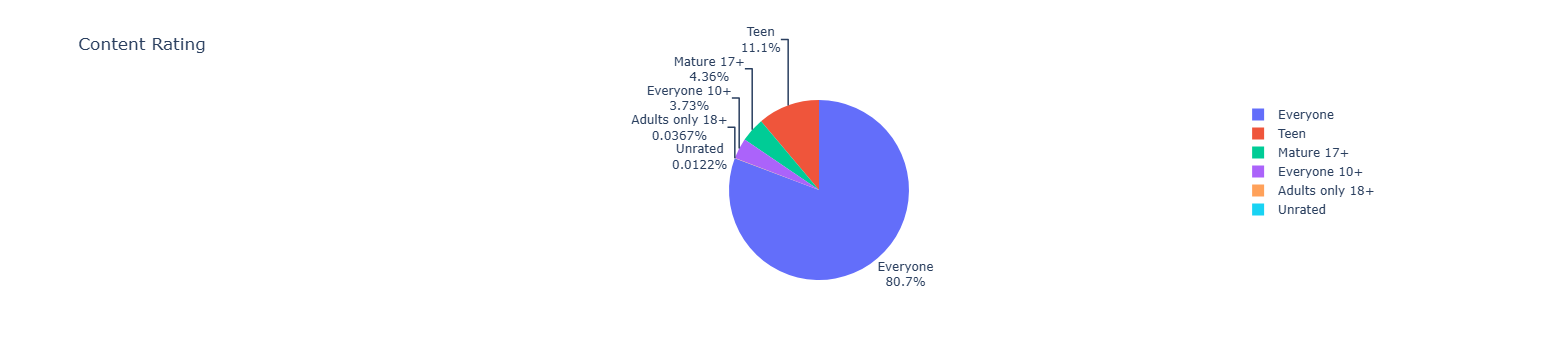

In [39]:
from play_store.presentation import charts

charts.content_rating_pie(df).show()

## Step 7: Content rating as a donut chart

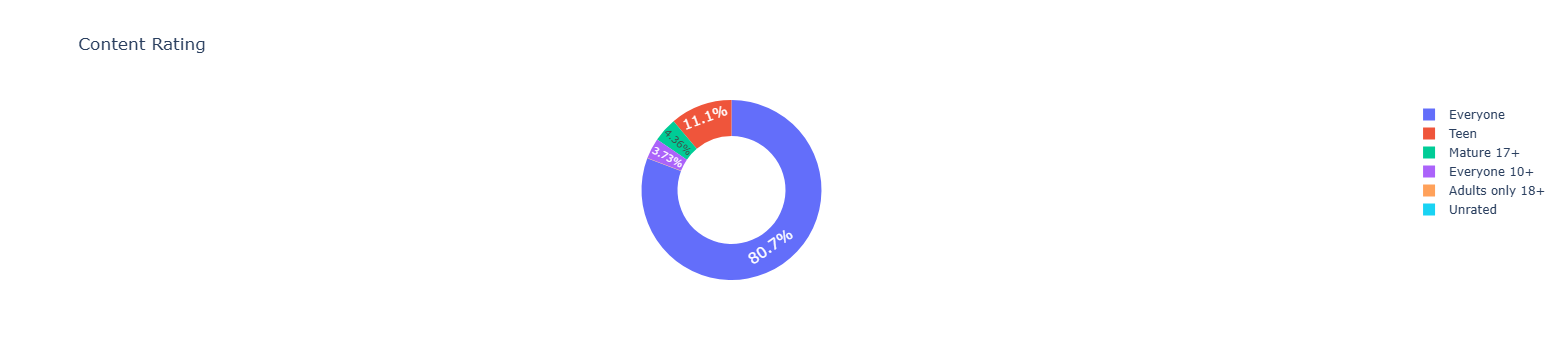

In [40]:
charts.content_rating_donut(df).show()

## Step 8: Categories with the most apps

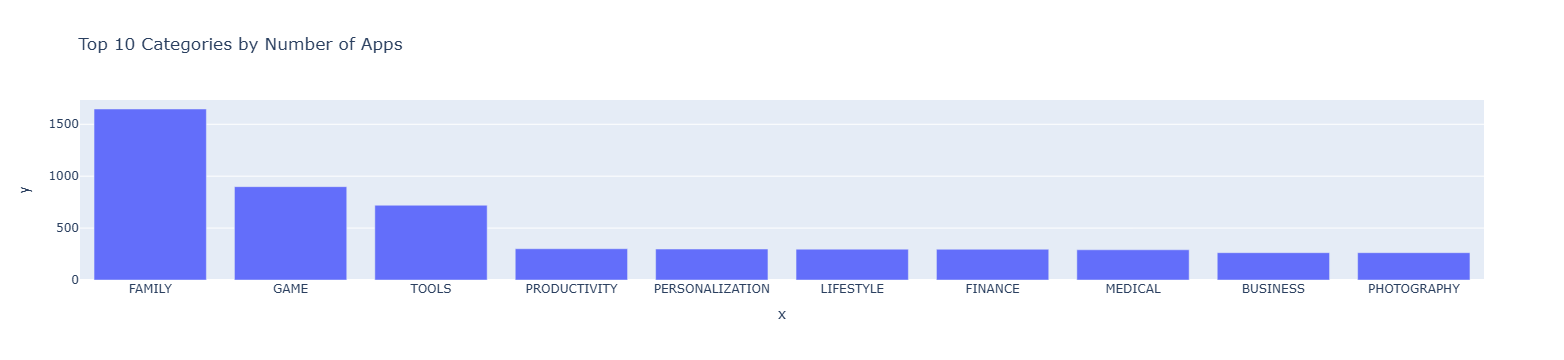

In [41]:
charts.top10_categories_bar(df).show()

## Step 9: Category popularity by installs

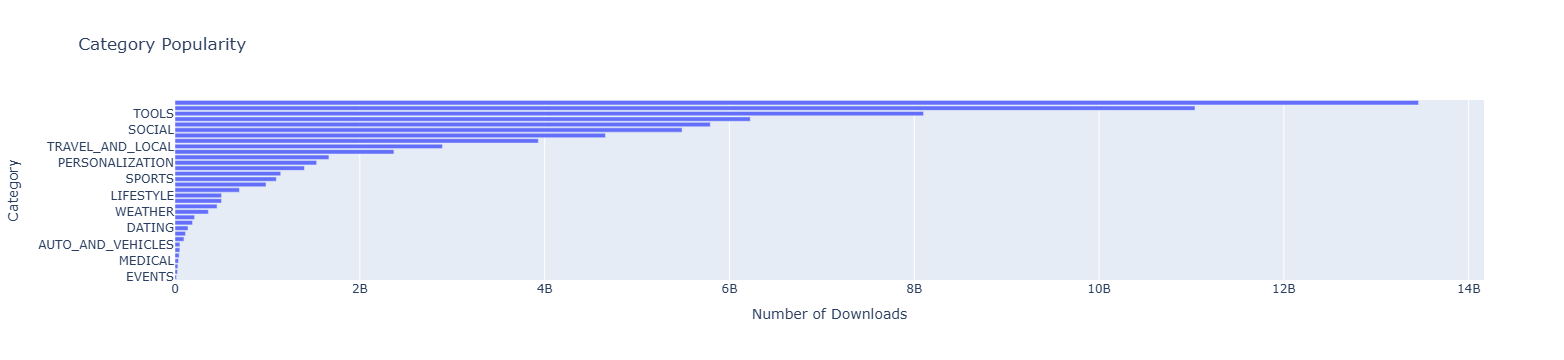

In [42]:
charts.category_popularity_bar(df).show()

## Step 10: Category concentration

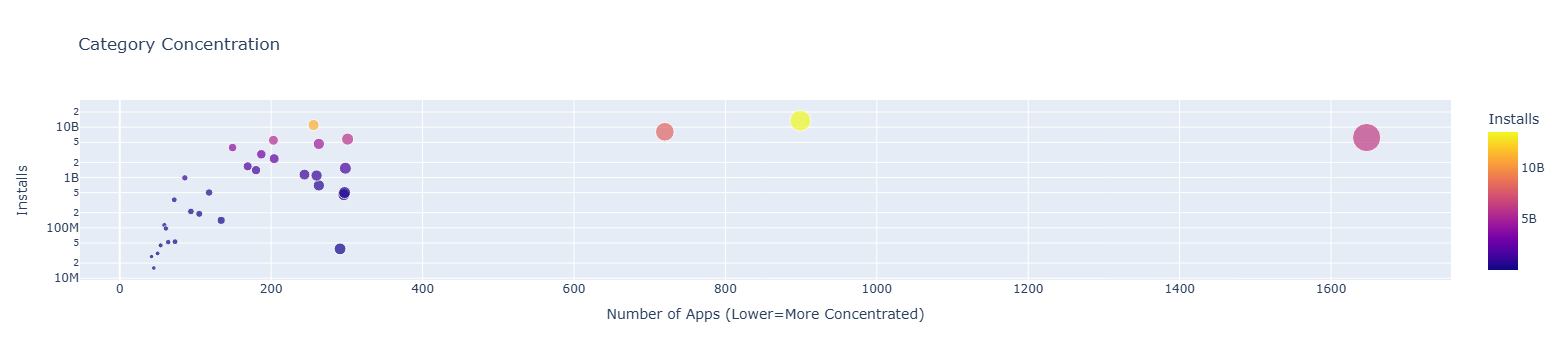

In [43]:
charts.category_concentration_scatter(df).show()

## Step 11: Top genres

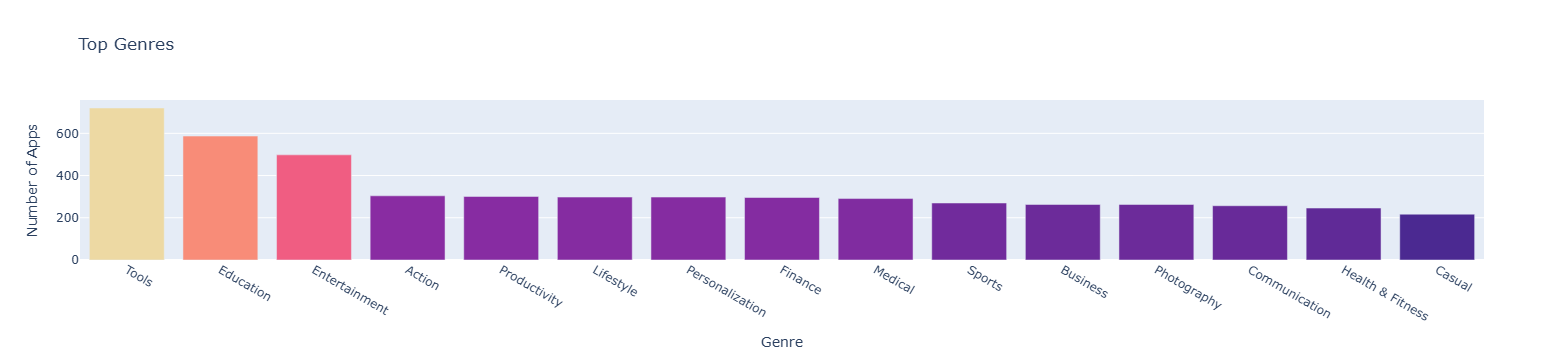

In [44]:
charts.top_genres_bar(df).show()

## Step 12: Free vs paid apps per category

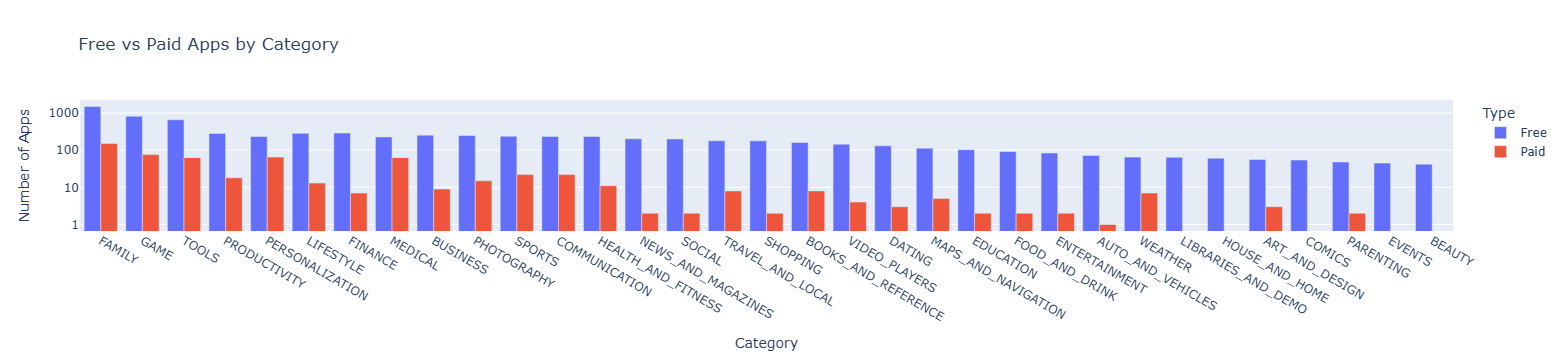

In [45]:
charts.free_vs_paid_bar(df).show()

## Step 13: Installs of free and paid apps

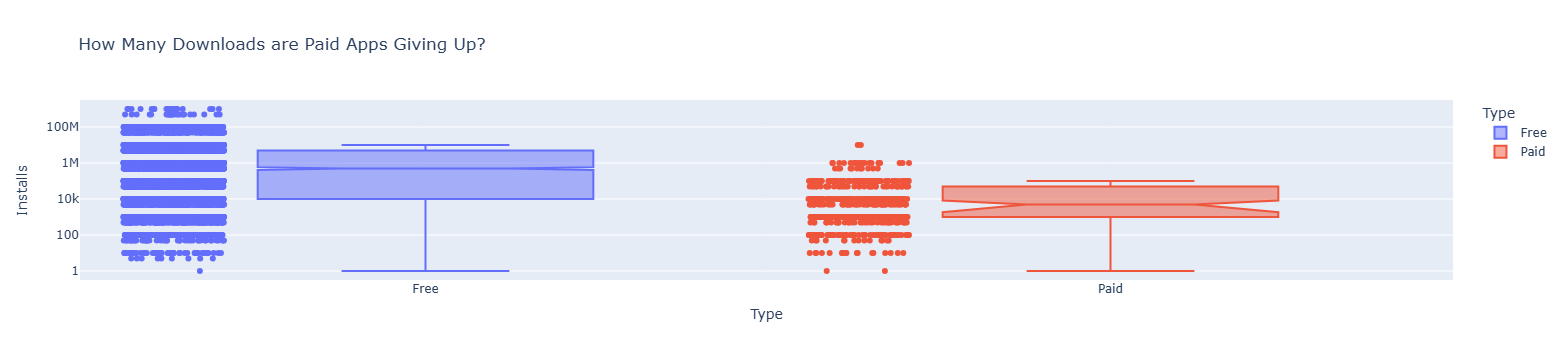

In [46]:
charts.installs_box(df).show()

## Step 14: Top grossing paid apps

In [47]:
top_grossing_paid_apps(df)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Revenue_Estimate
9220,Minecraft,FAMILY,4.5,2376564,19.000000,10000000,Paid,6.99,Everyone 10+,Arcade;Action & Adventure,69900000.0
8825,Hitman Sniper,GAME,4.6,408292,29.000000,10000000,Paid,0.99,Mature 17+,Action,9900000.0
7151,Grand Theft Auto: San Andreas,GAME,4.4,348962,26.000000,1000000,Paid,6.99,Mature 17+,Action,6990000.0
7477,Facetune - For Free,PHOTOGRAPHY,4.4,49553,48.000000,1000000,Paid,5.99,Everyone,Photography,5990000.0
7977,Sleep as Android Unlock,LIFESTYLE,4.5,23966,0.851562,1000000,Paid,5.99,Everyone,Lifestyle,5990000.0
6594,DraStic DS Emulator,GAME,4.6,87766,12.000000,1000000,Paid,4.99,Everyone,Action,4990000.0
6082,Weather Live,WEATHER,4.5,76593,4.750000,500000,Paid,5.99,Everyone,Weather,2995000.0
6856,Threema,COMMUNICATION,4.5,51110,3.500000,1000000,Paid,2.99,Everyone,Communication,2990000.0
7954,Bloons TD 5,FAMILY,4.6,190086,94.000000,1000000,Paid,2.99,Everyone,Strategy,2990000.0
7044,Tasker,TOOLS,4.6,43045,3.400000,1000000,Paid,2.99,Everyone,Tools,2990000.0


## Step 15: What paid apps earn

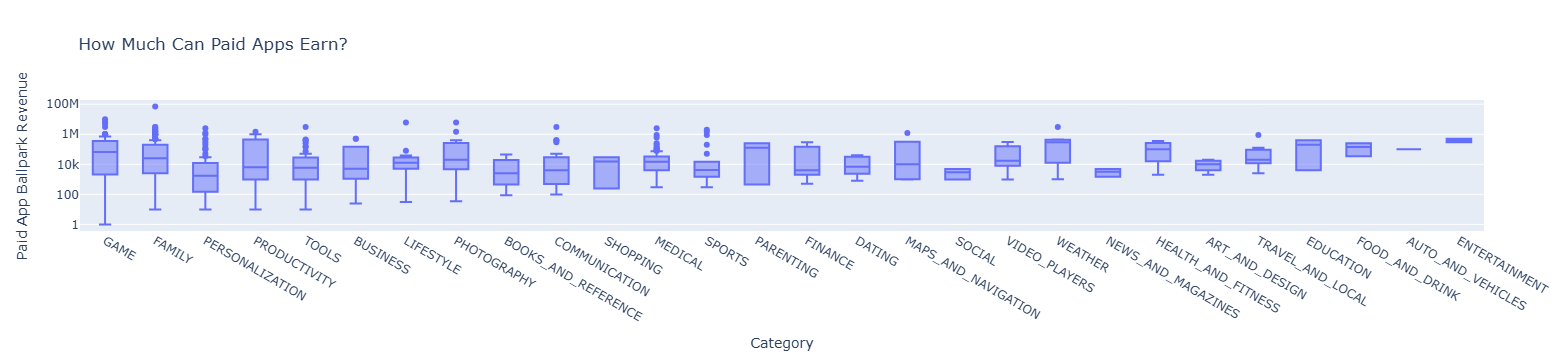

In [48]:
charts.paid_revenue_box(df).show()

## Step 16: What paid apps cost

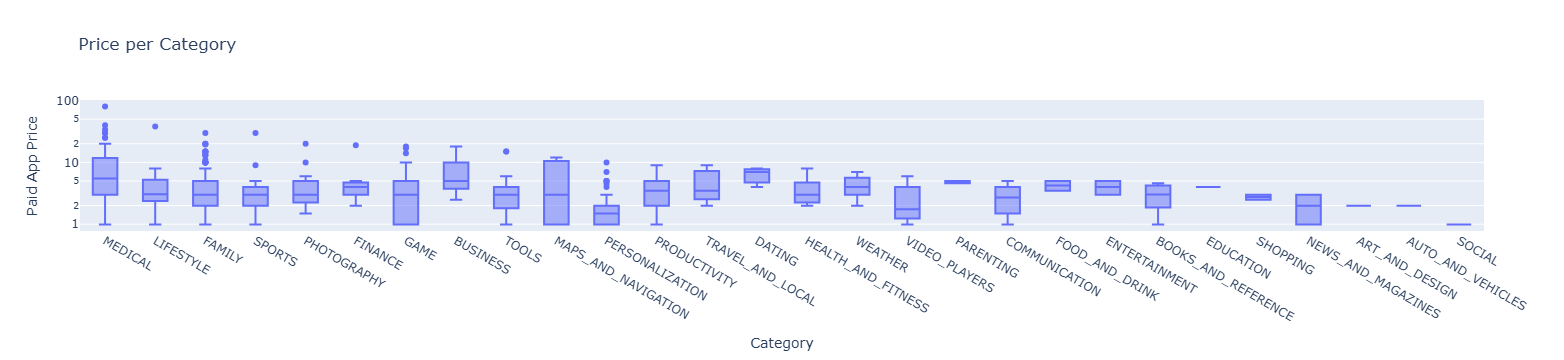

In [49]:
charts.paid_price_box(df).show()

In [50]:
from play_store.application.aggregations import median_paid_price

median_paid_price(df)

2.99